<a href="https://colab.research.google.com/github/Abeer-24/NLP/blob/main/Sentence_Embeddings_using_BERT_and_GPT_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install -q transformers torch scikit-learn

In [2]:
import torch
import numpy as np

from transformers import AutoTokenizer, AutoModel
from sklearn.metrics.pairwise import cosine_similarity

In [3]:
sentences = [
    "Machine learning is a part of artificial intelligence.",
    "Artificial intelligence includes machine learning.",
    "Cricket is a popular sport.",
    "Deep learning uses neural networks."
]

print("Input Sentences:\n")

for i, sentence in enumerate(sentences):
    print(i + 1, sentence)

Input Sentences:

1 Machine learning is a part of artificial intelligence.
2 Artificial intelligence includes machine learning.
3 Cricket is a popular sport.
4 Deep learning uses neural networks.


In [4]:
bert_name = "google-bert/bert-base-uncased"

bert_tokenizer = AutoTokenizer.from_pretrained(bert_name)
bert_model = AutoModel.from_pretrained(bert_name)

bert_model.eval()

print("BERT Model Loaded Successfully")

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: google-bert/bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


BERT Model Loaded Successfully


In [5]:
def get_bert_embedding(sentence):
    inputs = bert_tokenizer(
        sentence,
        return_tensors="pt",
        padding=True,
        truncation=True,
        max_length=128
    )

    with torch.no_grad():
        outputs = bert_model(**inputs)

    # Mean pooling using attention mask
    token_embeddings = outputs.last_hidden_state
    mask = inputs["attention_mask"].unsqueeze(-1)

    embedding = (token_embeddings * mask).sum(dim=1)
    embedding = embedding / mask.sum(dim=1)

    return embedding.squeeze(0).numpy()


bert_embeddings = np.array([
    get_bert_embedding(sentence)
    for sentence in sentences
])

print("BERT Embedding Shape:", bert_embeddings.shape)

BERT Embedding Shape: (4, 768)


In [6]:
gpt_name = "openai-community/gpt2"

gpt_tokenizer = AutoTokenizer.from_pretrained(gpt_name)
gpt_model = AutoModel.from_pretrained(gpt_name)

gpt_model.eval()

# GPT-2 does not have a default padding token
gpt_tokenizer.pad_token = gpt_tokenizer.eos_token

print("GPT-2 Model Loaded Successfully")

config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  548MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

GPT-2 Model Loaded Successfully


In [7]:
def get_gpt2_embedding(sentence):
    inputs = gpt_tokenizer(
        sentence,
        return_tensors="pt",
        padding=True,
        truncation=True,
        max_length=128
    )

    with torch.no_grad():
        outputs = gpt_model(**inputs)

    token_embeddings = outputs.last_hidden_state
    mask = inputs["attention_mask"].unsqueeze(-1)

    embedding = (token_embeddings * mask).sum(dim=1)
    embedding = embedding / mask.sum(dim=1)

    return embedding.squeeze(0).numpy()


gpt_embeddings = np.array([
    get_gpt2_embedding(sentence)
    for sentence in sentences
])

print("GPT-2 Embedding Shape:", gpt_embeddings.shape)

GPT-2 Embedding Shape: (4, 768)


In [8]:
print("BERT Embedding (First Sentence):")
print(bert_embeddings[0])

print("\nGPT-2 Embedding (First Sentence):")
print(gpt_embeddings[0])

BERT Embedding (First Sentence):
[ 1.86978966e-01  1.03237480e-01 -2.75423974e-01  1.25664800e-01
  3.09743613e-01 -2.48166323e-01  4.63293046e-01  5.26771188e-01
  2.27671489e-01 -4.36167240e-01  4.43329066e-02 -2.88567513e-01
 -4.73068833e-01  9.59423743e-03 -5.34144580e-01 -1.55735563e-03
  1.79145381e-01  1.55020699e-01  3.41864675e-02  3.75253886e-01
 -2.85067827e-01  3.06255311e-01 -1.91298768e-01  5.32678902e-01
  3.36782008e-01 -2.10499093e-01 -1.10009581e-01  1.01788752e-01
  2.99263168e-02 -2.21858516e-01  1.25539005e-01  2.59490997e-01
 -4.02343094e-01 -2.66663134e-01 -2.47246149e-04 -1.19505618e-02
 -5.59246302e-01 -1.69227973e-01 -4.87260729e-01  5.14018536e-01
 -4.94977564e-01 -2.04352140e-01 -1.05658166e-01  2.81267613e-01
 -2.73013234e-01 -4.20154929e-01 -2.77484775e-01  9.68963355e-02
  3.15123349e-01 -8.64891857e-02 -1.11046648e+00  1.27130494e-01
 -3.54214199e-02  7.39418790e-02  3.19516391e-01  9.19854403e-01
  2.09346771e-01 -1.54774055e-01  8.12400952e-02 -7.05292

In [9]:
bert_similarity = cosine_similarity(bert_embeddings)

print("BERT Cosine Similarity Matrix:")
print(np.round(bert_similarity, 3))

BERT Cosine Similarity Matrix:
[[1.    0.888 0.556 0.83 ]
 [0.888 1.    0.521 0.883]
 [0.556 0.521 1.    0.5  ]
 [0.83  0.883 0.5   1.   ]]


In [10]:
gpt_similarity = cosine_similarity(gpt_embeddings)

print("GPT-2 Cosine Similarity Matrix:")
print(np.round(gpt_similarity, 3))

GPT-2 Cosine Similarity Matrix:
[[1.    0.999 0.997 0.998]
 [0.999 1.    0.995 0.999]
 [0.997 0.995 1.    0.997]
 [0.998 0.999 0.997 1.   ]]


In [11]:
import pandas as pd

comparison = pd.DataFrame({
    "Sentence": sentences,
    "BERT Embedding Size": [bert_embeddings.shape[1]] * len(sentences),
    "GPT-2 Embedding Size": [gpt_embeddings.shape[1]] * len(sentences)
})

display(comparison)

,Sentence,BERT Embedding Size,GPT-2 Embedding Size
0,Machine learning is a part of artificial intel...,768,768
1,Artificial intelligence includes machine learn...,768,768
2,Cricket is a popular sport.,768,768
3,Deep learning uses neural networks.,768,768


In [12]:
sentence1 = 0
sentence2 = 1

print("Sentence 1:", sentences[sentence1])
print("Sentence 2:", sentences[sentence2])

print("\nBERT Similarity:",
      round(float(bert_similarity[sentence1, sentence2]), 4))

print("GPT-2 Similarity:",
      round(float(gpt_similarity[sentence1, sentence2]), 4))

Sentence 1: Machine learning is a part of artificial intelligence.
Sentence 2: Artificial intelligence includes machine learning.

BERT Similarity: 0.8879
GPT-2 Similarity: 0.9989


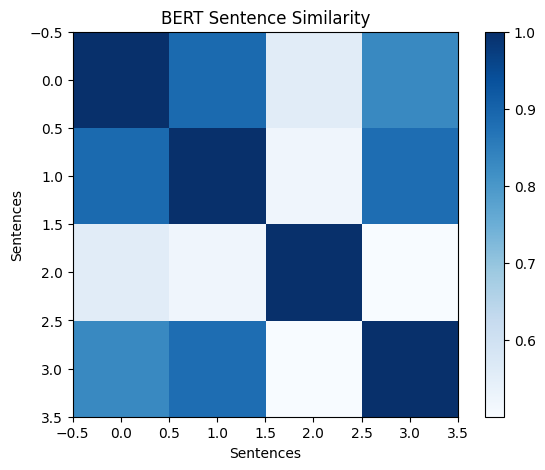

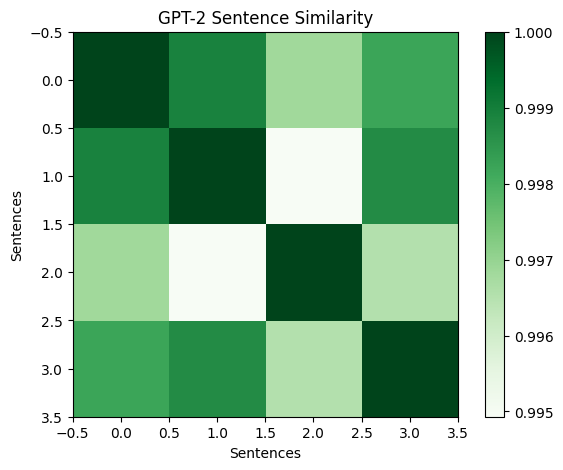

In [13]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 5))
plt.imshow(bert_similarity, cmap="Blues")
plt.colorbar()

plt.title("BERT Sentence Similarity")
plt.xlabel("Sentences")
plt.ylabel("Sentences")
plt.show()

plt.figure(figsize=(7, 5))
plt.imshow(gpt_similarity, cmap="Greens")
plt.colorbar()

plt.title("GPT-2 Sentence Similarity")
plt.xlabel("Sentences")
plt.ylabel("Sentences")
plt.show()